In [15]:
import pandas as pd

data = pd.read_csv(r"C:\Users\USER\Downloads\POS_Project\POS_transactions.csv")

# Show all columns clearly
pd.set_option('display.max_columns', None)

# Increase width of the table display
pd.set_option('display.width', 1000)

# Prevent text from being cut off
pd.set_option('display.max_colwidth', 50)

# Display first 5 rows neatly
data.head()



,Timestamp,Section A - Basic Information\n1. What is your POS Provider?,2. How long have you worked as a POS agent?,3. Location/Area of operation,Section B - Failed Transaction Experience \n4. How often do failed POS transactions occur?\n,5. What transaction type fails most?,6. What is the most common cause?,7. Average amount usually affected?,8. How long do reversals usually take?,9. Which banks experience the most delays?,10. What action do you usually take?,Section C - Impact\n11. Have delayed reversals affected your business?,12. Biggest effect of failed transactions?,13. What solution would help most
0,5/9/2026 6:18:45,Moniepoint,1-3 years,Rukuba road,Weekly,Withdrawal,Poor network,20000,1-3 days,UBA,Wait,Yes,Arguments/conflicts,Faster alerts
1,5/9/2026 7:37:45,Moniepoint,Less than 1 year,Satellite market,Rarely,Transfer,Poor network,NaN,1-24 hours,NaN,Call support,Yes,Customer loss,Network improvement
2,5/9/2026 7:44:43,Moniepoint,Less than 1 year,Osun State,Rarely,Withdrawal,POS machine issue,"#150,000",More than 3 days,First bank,Retry,Yes,Arguments/conflicts,Network improvement
3,5/9/2026 7:54:23,Opay,3+ years,Bukuru gyel,Rarely,Transfer,Poor network,50k,Less than 1 hour,Access bank,Call support,Yes,Arguments/conflicts,Network improvement
4,5/9/2026 7:55:07,Moniepoint,Less than 1 year,"Jos plateau state, kabong-tudun wada road",Rarely,Transfer,Poor network,20000,More than 3 days,Gtbank,Call support,Yes,Delay in operations,Network improvement


In [2]:
data.shape
data.columns
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 14 columns):
 #   Column                                                                                      Non-Null Count  Dtype 
---  ------                                                                                      --------------  ----- 
 0   Timestamp                                                                                   23 non-null     object
 1   Section A - Basic Information
1. What is your POS Provider?                                 22 non-null     object
 2   2. How long have you worked as a POS agent?                                                 21 non-null     object
 3   3. Location/Area of operation                                                               19 non-null     object
 4   Section B - Failed Transaction Experience 
4. How often do failed POS transactions occur?
  22 non-null     object
 5   5. What transaction type fails most?                

In [5]:
import pandas as pd

data = pd.read_csv(r"C:\Users\USER\Downloads\POS_Project\POS_transactions.csv")

data.isnull().sum()

data.fillna("Not Provided", inplace=True)

print(data.isnull().sum())


Timestamp                                                                                       0
Section A - Basic Information\n1. What is your POS Provider?                                    0
2. How long have you worked as a POS agent?                                                     0
3. Location/Area of operation                                                                   0
Section B - Failed Transaction Experience \n4. How often do failed POS transactions occur?\n    0
5. What transaction type fails most?                                                            0
6. What is the most common cause?                                                               0
7. Average amount usually affected?                                                             0
8. How long do reversals usually take?                                                          0
9. Which banks experience the most delays?                                                      0
10. What action do y

In [6]:
data["6. What is the most common cause?"].value_counts()

6. What is the most common cause?
Poor network         18
POS machine issue     2
Bank server issue     2
Not Provided          1
Name: count, dtype: int64

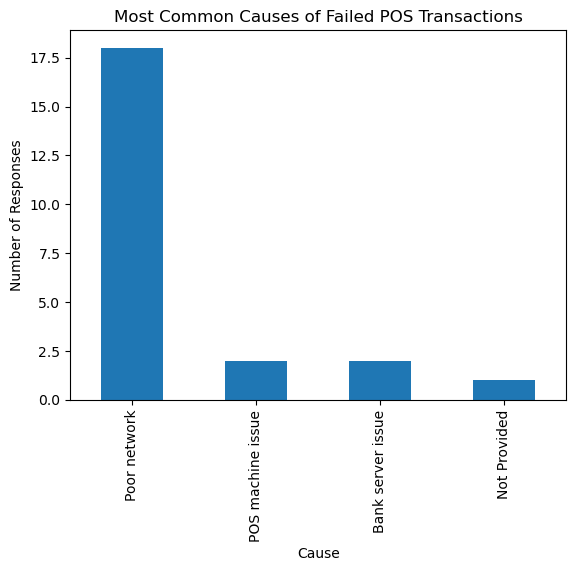

In [8]:
import matplotlib.pyplot as plt

causes = data["6. What is the most common cause?"].value_counts()

causes.plot(kind="bar")

plt.title("Most Common Causes of Failed POS Transactions")
plt.xlabel("Cause")
plt.ylabel("Number of Responses")

plt.show()

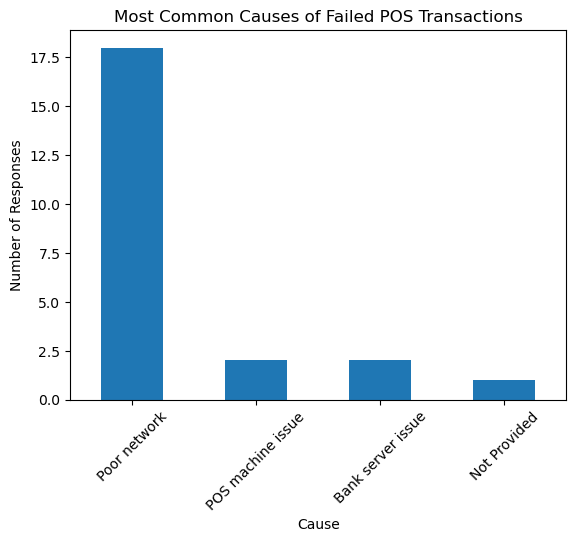

In [11]:
import matplotlib.pyplot as plt

causes = data["6. What is the most common cause?"].value_counts()

causes.plot(kind="bar")

plt.title("Most Common Causes of Failed POS Transactions")
plt.xlabel("Cause")
plt.ylabel("Number of Responses")

plt.xticks(rotation=45)

plt.show()

In [12]:
data["8. How long do reversals usually take?"].value_counts()

8. How long do reversals usually take?
1-24 hours          9
1-3 days            7
Less than 1 hour    4
More than 3 days    2
Not Provided        1
Name: count, dtype: int64

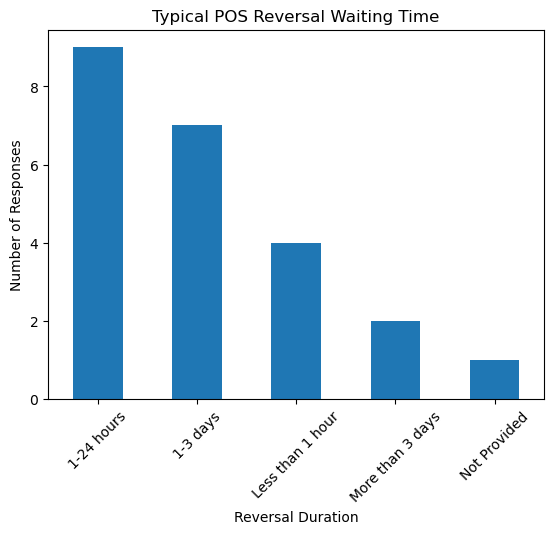

In [13]:
reversal_time = data["8. How long do reversals usually take?"].value_counts()

reversal_time.plot(kind="bar")

plt.title("Typical POS Reversal Waiting Time")
plt.xlabel("Reversal Duration")
plt.ylabel("Number of Responses")

plt.xticks(rotation=45)

plt.show()

In [4]:
import pandas as pd

data = pd.read_csv(r"C:\Users\USER\Downloads\POS_Project\POS_transactions.csv")


data["9. Which banks experience the most delays?"].value_counts()

9. Which banks experience the most delays?
UBA                                    4
Access bank                            2
Union Bank                             2
Gtbank                                 1
First bank                             1
GT bank                                1
Access Bank, First Bank and GT Bank    1
Union bank                             1
GT Bank                                1
First Bank                             1
Zenith                                 1
Gt                                     1
All                                    1
Name: count, dtype: int64

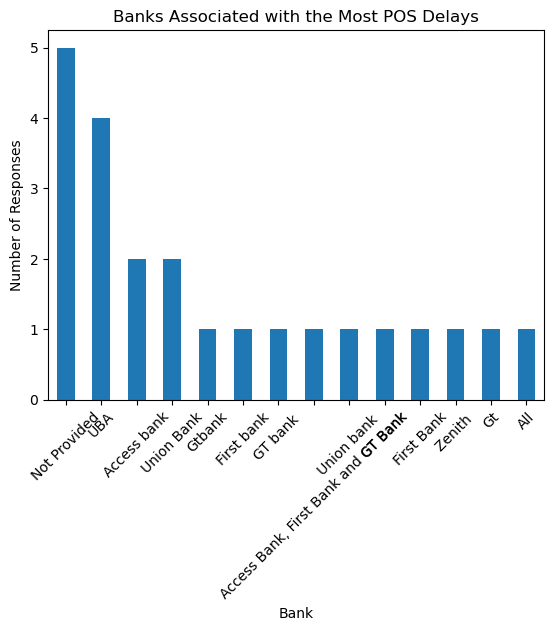

In [15]:
bank_delays = data["9. Which banks experience the most delays?"].value_counts()

bank_delays.plot(kind="bar")

plt.title("Banks Associated with the Most POS Delays")
plt.xlabel("Bank")
plt.ylabel("Number of Responses")

plt.xticks(rotation=45)

plt.show()

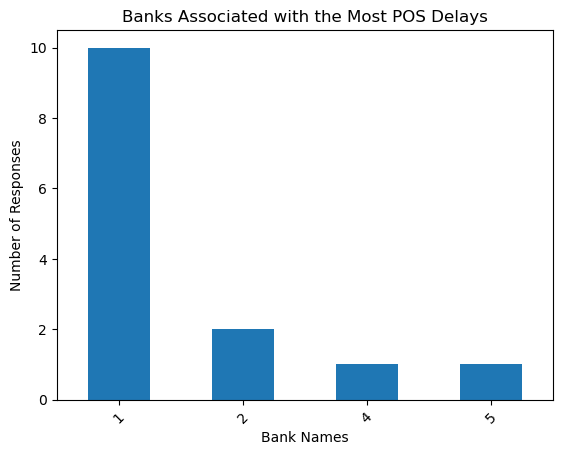

In [20]:
bank_delays = data["9. Which banks experience the most delays?"].value_counts()

#Remove missing responses
bank_delays = bank_delays[bank_delays != "Not Provided"]

#Count bank names
bank_counts = bank_delays.value_counts()

# Plot chart
bank_counts.plot(kind="bar")

plt.title("Banks Associated with the Most POS Delays")
plt.xlabel("Bank Names")
plt.ylabel("Number of Responses")

plt.xticks(rotation=45)

plt.show()

In [21]:
print(bank_delays.unique())

[5 4 2 1]


In [23]:
bank_delays = data["9. Which banks experience the most delays?"]

#Remove missing responses
bank_delays = bank_delays[bank_delays != "Not Provided"]

#Convert everything to text
bank_delays = bank_delays.astype(str)

#Remove extra spaces
bank_delays = bank_delays.str.strip()

#Count responses
bank_counts = bank_delays.value_counts()

print(bank_counts)

9. Which banks experience the most delays?
UBA                                    4
Access bank                            2
Union Bank                             2
Gtbank                                 1
First bank                             1
GT bank                                1
Access Bank, First Bank and GT Bank    1
Union bank                             1
GT Bank                                1
First Bank                             1
Zenith                                 1
Gt                                     1
All                                    1
Name: count, dtype: int64


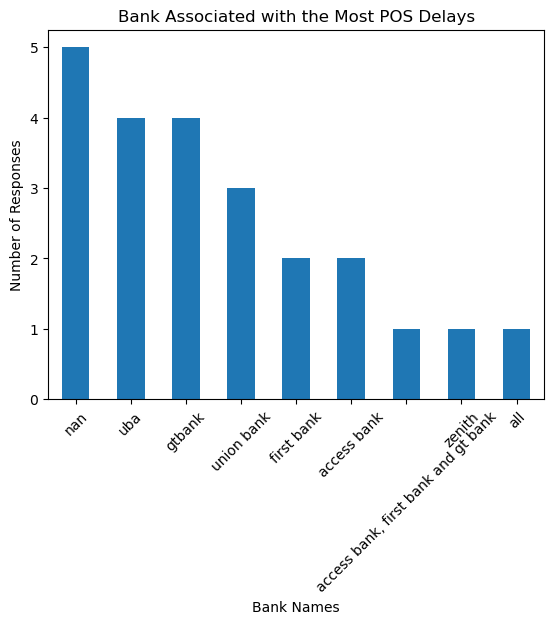

In [7]:
import matplotlib.pyplot as plt

bank_delays = data["9. Which banks experience the most delays?"]

#Remove missing responses
bank_delays = bank_delays[bank_delays != "Not Provided"]

#Convert everything to text
bank_delays = bank_delays.astype(str)

#Remove extra spaces
bank_delays = bank_delays.str.strip()

#Convert all names to lowercase
bank_delays = bank_delays.str.lower()

#Standardize similar names
bank_delays = bank_delays.replace({
    "gt": "gtbank",
    "gt bank": "gtbank",
    "access bank": "access bank",
    "first bank": "first bank",
    "union bank": "union bank"
})
#Count responses
bank_counts = bank_delays.value_counts()

#Plot chart
bank_counts.plot(kind="bar")

plt.title("Bank Associated with the Most POS Delays")
plt.xlabel("Bank Names")
plt.ylabel("Number of Responses")

plt.xticks(rotation=45)

plt.show()

In [5]:
import pandas as pd

data = pd.read_csv(r"C:\Users\USER\Downloads\POS_Project\POS_transactions.csv")

data["13. What solution would help most"].value_counts()

13. What solution would help most
Network improvement    15
Better support          3
Reversal prediction     3
Faster alerts           1
Name: count, dtype: int64

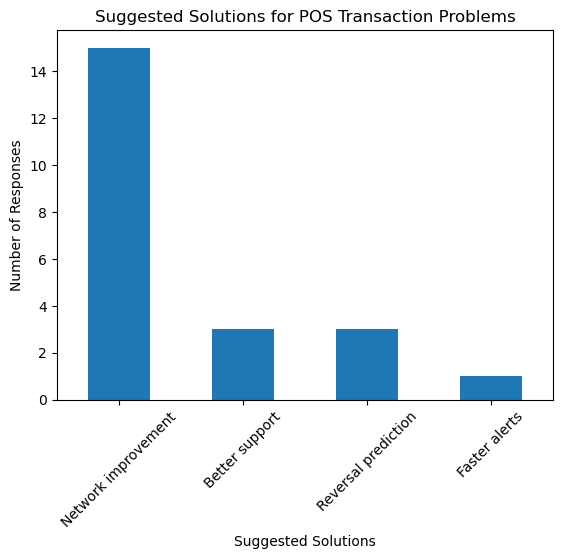

In [8]:
import matplotlib.pyplot as plt

solutions = data["13. What solution would help most"].value_counts()

solutions.plot(kind="bar")

plt.title("Suggested Solutions for POS Transaction Problems")
plt.xlabel("Suggested Solutions")
plt.ylabel("Number of Responses")

plt.xticks(rotation=45)

plt.show()

# Analysis of Bank Delays
The analysis shows that some banks were reported more frequently for POS transaction delays.
UBA had the highest number of reported delays, followed by GTBankand Access Bank.
This suggests that networkissues or transaction processing delays may be more common with these banks during POS operations.

# Key Findings
1. Poor network was the most common cause of failed POS transaction
2. Most POS reversals were completed witin 24 hours.
3. GTBank and UBA were among the banks most associated with POS delays.
4. Failed transactions negatively affected business operations for many POS agents.

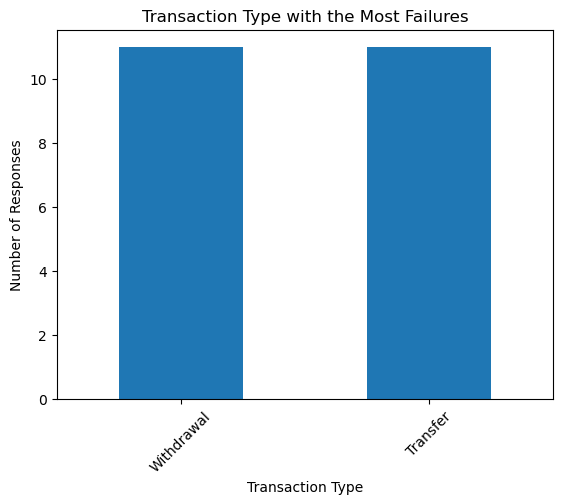

In [10]:
transaction_type = data["5. What transaction type fails most?"].value_counts()

transaction_type.plot(kind="bar")

plt.title("Transaction Type with the Most Failures")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Responses")

plt.xticks(rotation=45)

plt.show()


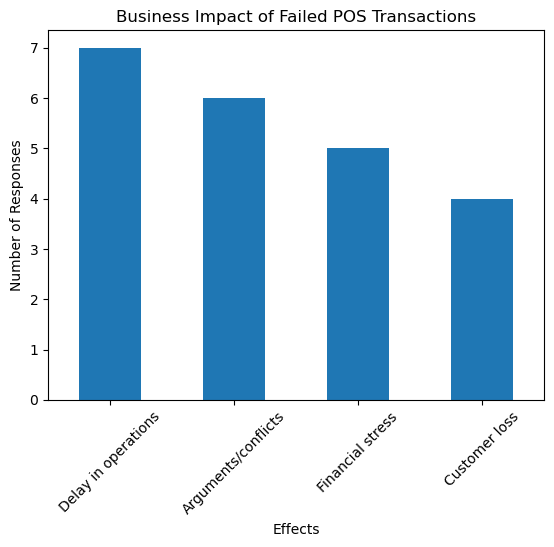

In [13]:
import matplotlib.pyplot as plt

impact = data["12. Biggest effect of failed transactions?"].value_counts()

impact.plot(kind="bar")

plt.title("Business Impact of Failed POS Transactions")
plt.xlabel("Effects")
plt.ylabel("Number of Responses")

plt.xticks(rotation=45)

plt.show()

# Business Impact Analysis

The findings show that failed POS transactions negatively affect business operations.
Many POS agents reported customer dissatisfaction, delayed business activities, and financial stress as major effects of failed transactions.
This indicates that transaction failures can reduce customer trust and affect daily business performance.

In [ ]:
 # Recommendations
1. Banks should improve network stability to reduce failed transactions.
2. POS service providers should speed up reversal processing times.
3. Customers should receive faster transaction alerts and updates.
4. Banks should improve customer support for transaction complaints.
5. Regular maintenance of POS terminals should be encouraged.

# Conclusion
This project analyzed the causes and effects of failed POS transactions using survey data from POS agents.
The findings revealed that poor network issues were the major cause of transaction failures, while delays in reversals affected both businesses and customers.
The analysis also showed that improving banking systems, network reliability, and customer support could help reduce POS transaction problems.